# Fashion-MNIST Clothing Classification

## Imports

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import fashion_mnist

import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics import ConfusionMatrixDisplay

## a) Load Data

In [3]:
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Select subset of 12,000 samples
X_subset, _, y_subset, _ = train_test_split(
    X_train, y_train,
    train_size=12_000,
    stratify=y_train,
    random_state=42)

This code selects a subset of 12,000 images from the 60,000 image original training set.

### Training testing split

In [6]:
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_subset,
    y_subset,
    test_size=0.20,
    stratify=y_subset,
    random_state=42,)

splits = {
    "Training": (X_train_sub, y_train_sub),
    "Validation": (X_val, y_val),
    "Test": (X_test, y_test)}

This code splits the 12,000 image subset into 80% training and 20% validation data. The 10,000 original test images are left untouched.

### Flatten images

In [12]:
X_train_sub = X_train_sub.reshape(-1, 784)
X_val = X_val.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

Ordinary logistic regression expects each image as a one-dimensional feature vector, so flattening its 28x28 pixels gives 784 input features. Rescaling pixel values to 0-1 keeps feature magnitudes manageable, which generally helps optimization converge more reliably.

### Report shape and class counts

In [7]:
rows = []
for name, (X, y) in splits.items():
    counts = pd.Series(y).value_counts().reindex(range(10), fill_value=0)
    rows.append({
        "Split": name,
        "X shape": X.shape,
        "y shape": y.shape,
        **{f"Class {c}": counts[c] for c in range(10)},
    })

display(pd.DataFrame(rows).set_index("Split"))

,X shape,y shape,Class 0,Class 1,Class 2,Class 3,Class 4,Class 5,Class 6,Class 7,Class 8,Class 9
Split,,,,,,,,,,,,
Training,"(9600, 28, 28)","(9600,)",960,960,960,960,960,960,960,960,960,960
Validation,"(2400, 28, 28)","(2400,)",240,240,240,240,240,240,240,240,240,240
Test,"(10000, 784)","(10000,)",1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


### Display one labeled image from each class

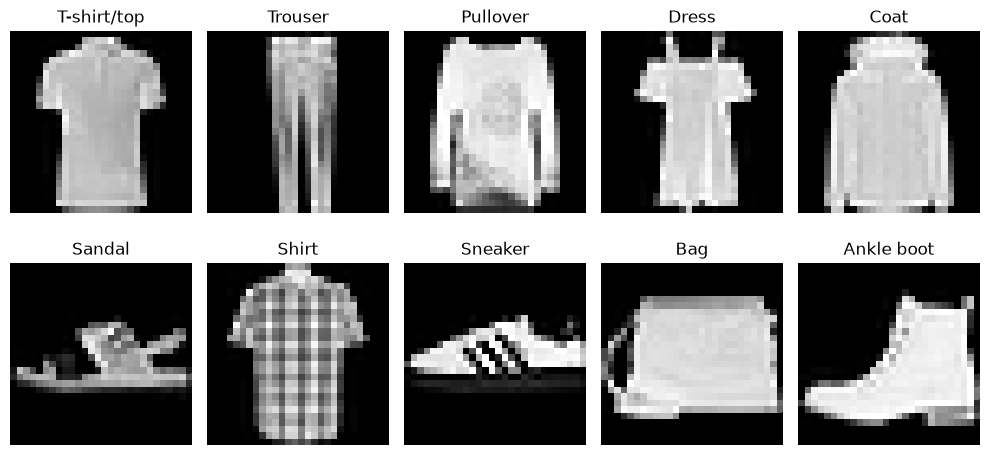

In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for label, ax in enumerate(axes.flat):
    i = np.flatnonzero(y_train_sub == label)[0]
    ax.imshow(X_train_sub[i].reshape(28, 28), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## b) Multinomial logistic regression

In [ ]:
models = {}
results = []

for C in (0.01, 0.1, 1.0):
    model = LogisticRegression(
        solver="lbfgs",
        penalty="l2",
        C=C,
        max_iter=3000,
        random_state=42)

    # Surface any convergence warning rather than silently ignoring it.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train_sub, y_train_sub)

    for warning in caught:
        print(f"C={C}: {warning.message}")

    models[C] = model
    results.append({
        "Penalty": "L2",
        "C": C,
        "Validation accuracy": accuracy_score(y_val, model.predict(X_val))})

results = pd.DataFrame(results)

best_C = results.loc[results["Validation accuracy"].idxmax(), "C"]
best_model = models[best_C]

test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)

C=0.01: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
C=0.01: lbfgs failed to converge after 3000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=3000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
C=0.1: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use

,Penalty,C,Validation accuracy
0,L2,0.01,0.771667
1,L2,0.10,0.764167
2,L2,1.00,0.764167


Selected model: L2, C=0.01
Test accuracy: 0.7558
Test macro-F1: 0.7562
Test log loss: 3.3213


`results["Validation accuracy"].idxmax()` finds the row index with the highest validation accuracy. The corresponding `c` is assigned to `best_c`. `models[best_c]` retrieves the already-fitted model with that regularization setting. `predict(x_test)` predicts a clothing class for each test image; `predict(x_test)` predicts a clothing class for each test image; `predict_proba(x_test)` returns the probabilities for each class. Test accuracy is the fraction of predictions that are correct. Macro-F1 calculates F1 for each class, then averages them equally, so each clothing category matters equally. Log loss evaluates the predicted probabilities, penalizing confident incorrect predictions more heavily. Passing `best_model.classes_` ensures the probability columns are matched to the right class labels.

In [15]:
display(results)

print(f"Selected model: L2, C={best_C}")

print(f"Test accuracy: {accuracy_score(y_test, test_pred):.4f}")
print(f"Test macro-F1: {f1_score(y_test, test_pred, average='macro'):.4f}")
print(f"Test log loss: {log_loss(y_test, test_prob, labels=best_model.classes_):.4f}")

,Penalty,C,Validation accuracy
0,L2,0.01,0.771667
1,L2,0.10,0.764167
2,L2,1.00,0.764167


Selected model: L2, C=0.01
Test accuracy: 0.7558
Test macro-F1: 0.7562
Test log loss: 3.3213


The L2 model with C = 0.01 performed the best on validation data, with 77.2% accuracy, so it was selected. Its test accuracy was 75.6%, with similar macro-F1 of 0.756, indicating broadly balanced performance across the ten classes. The test accuracy being slightly lower than validation is a modest generalization drop. 

The log loss of 3.32 is relatively high, meaning the predicted probabilities are often not well-calibrated and/or the model makes some confident mistakes, even though its class predictions are correct about three-quarters of the time. 

## Confusion matrix

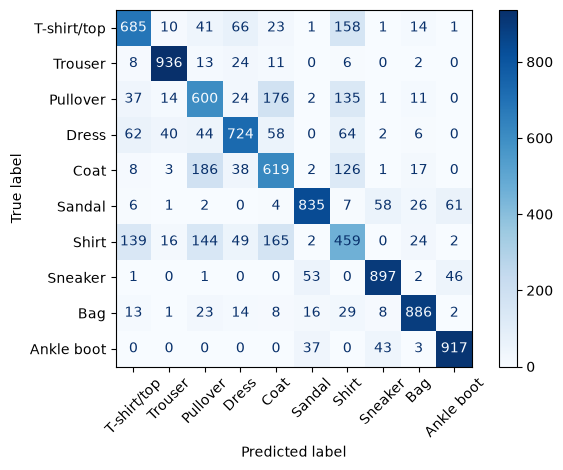

In [17]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues")
plt.tight_layout()
plt.show()

The model frequently confuses  `Pullover` and `Coat`, with 176 pullovers misclassified as coats and 186 coats misclassified as pullovers. These classes have similar visual features. Another frequent confusion is `Shirt` and `T-shirt/top`, with 139 shirts misclassified as `T-shirts/tops` and 158 `T-shirts/tops` misclassified as shirts. 

## d) 

c:\Users\codett\anaconda3\envs\Energy-Disaggregation\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Test accuracy:  0.7655
Shirt precision: 0.7642
Shirt recall:    0.7680
Shirt F1:        0.7661


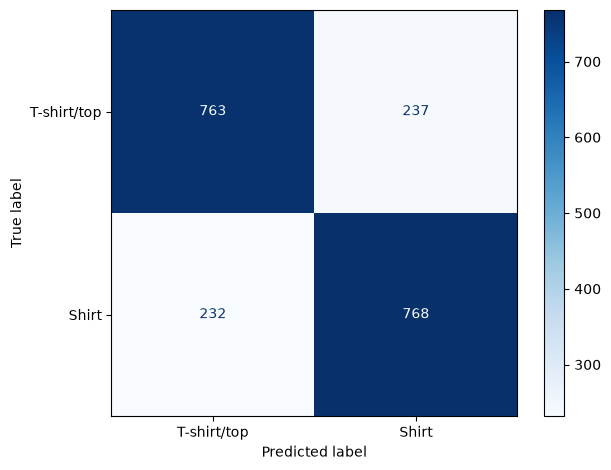

In [19]:
def filter_binary(X, y):
    mask = np.isin(y, [0, 6])
    X_filtered = X[mask]
    y_binary = (y[mask] == 6).astype(int)  # T-shirt/top=0, shirt=1
    return X_filtered, y_binary

X_train_bin, y_train_bin = filter_binary(X_train_sub, y_train_sub)
X_val_bin, y_val_bin = filter_binary(X_val, y_val)  # Filtered, not used for fitting
X_test_bin, y_test_bin = filter_binary(X_test, y_test)

model_bin = LogisticRegression(solver="lbfgs", C=0.01, penalty="l2", max_iter=3000, random_state=42)
model_bin.fit(X_train_bin, y_train_bin)

# Predict shirt (class 1) when its sigmoid probability is at least 0.5
shirt_prob = model_bin.predict_proba(X_test_bin)[:, 1]
y_pred_bin = (shirt_prob >= 0.5).astype(int)

print(f"Test accuracy:  {accuracy_score(y_test_bin, y_pred_bin):.4f}")
print(f"Shirt precision: {precision_score(y_test_bin, y_pred_bin):.4f}")
print(f"Shirt recall:    {recall_score(y_test_bin, y_pred_bin):.4f}")
print(f"Shirt F1:        {f1_score(y_test_bin, y_pred_bin):.4f}")

ConfusionMatrixDisplay(
    confusion_matrix(y_test_bin, y_pred_bin, labels=[0, 1]),
    display_labels=["T-shirt/top", "Shirt"],
).plot(cmap="Blues")
plt.tight_layout()
plt.show()

The binary logistic regression model acheived a test accuracy of 76.55%, with a precision of 76.42%, recall of 76.80%, and F1-score of 76.61% for Shirt. The confusion matrix shows that 768 Shirt images were correctly classified, while 232 were misclassified as T-shirt/top. Of the T-shirt/top images, 763 were correctly classified and 237 were incorrectly predicted as Shirt. The similar precision and recall indicate tha the model performs comparably in avoiding false positive Shirt predictions and identifying actual Shirt images.

Unlike the ten-class softmax model, which outputs a probability distribution across all ten clothing classes, binary logistic regression uses a sigmoid function to estimate the probability that an image belongs to Shirt rather than T-shirt/top. With a threshold of 0.5, images with a predicted Shirt probability of at least 0.5 are classified as Shirt, and the rest as T-shirt/top. This simplifies the classification task but limits the model to distinguishing between these two classes.